# Lucas-Kanade sobre un vídeo

Notebook basado en el paper de Lucas y Kanade (1981). No hago el algoritmo completo, solo la parte de **resolver la ecuación** en una ventana alrededor de cada punto.

La idea del paper en corto:

- $F$ es la imagen nueva y $G$ la anterior. Buscamos el desplazamiento $h$ que cumple $G(x) = F(x + h)$.
- Si $h$ es pequeño: $F(x+h) \approx F(x) + h \, \partial F / \partial x$.
- Minimizando el error L2 en una ventana $R$ queda:

$$h = \left( \sum_{x \in R} \nabla F \, \nabla F^T \right)^{-1} \sum_{x \in R} \nabla F \,[G(x) - F(x)]$$

En 2D esto es un sistema de 2x2 con cinco sumas (las que menciona el paper): $\sum F_x^2$, $\sum F_y^2$, $\sum F_x F_y$, $\sum (G-F)F_x$ y $\sum (G-F)F_y$.

Pasos:
1. Poner la ruta del vídeo y leer dos frames seguidos
2. Pasar a gris y suavizar
3. Calcular las derivadas
4. Resolver la ecuación en un punto
5. Hacerlo en varios puntos y dibujar las flechas
6. Aplicarlo a todo el vídeo

In [22]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

#### Lectura de Frames

In [23]:
# >>>>>>>>>>  PONER AQUÍ LA RUTA DEL VÍDEO  <<<<<<<<<<
RUTA_VIDEO = "new_york.mp4"     # ejemplo: "people2.mp4"  (o 0 para la webcam)

cap = cv2.VideoCapture(RUTA_VIDEO)
ok1, frame_ant = cap.read()     # frame anterior  -> G
ok2, frame_nue = cap.read()     # frame nuevo     -> F
cap.release()

if not (ok1 and ok2):
    print("No se han podido leer dos frames, revisa la ruta del vídeo")
else:
    print("Tamaño del frame:", frame_ant.shape)

Tamaño del frame: (720, 1280, 3)


#### Escala de Grises y Suavizado

In [24]:
def preparar(frame):
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    return gris.astype(np.float32)      # float para que las restas no den problemas

G = preparar(frame_ant)    # imagen anterior
F = preparar(frame_nue)    # imagen nueva

#### Derivadas

Se estima la derivada con una diferencia entre píxeles vecinos, con $\Delta x$ de un píxel:

$$F'(x) \approx \frac{F(x+\Delta x) - F(x)}{\Delta x}$$


In [25]:
def derivadas(F, G):
    Fx = np.zeros_like(F)
    Fy = np.zeros_like(F)
    Fx[:, :-1] = F[:, 1:] - F[:, :-1]      # derivada en x (columna siguiente - actual)
    Fy[:-1, :] = F[1:, :] - F[:-1, :]      # derivada en y (fila siguiente - actual)
    dif = G - F                            # G - F
    return Fx, Fy, dif

Fx, Fy, dif = derivadas(F, G)

#### Resolver la ecuación en un punto

In [26]:
R = 7                    # radio de la ventana -> ventana de 15x15
UMBRAL_DET = 1e4         # si el determinante es menor, no nos fiamos (valor a ojo, se puede cambiar)
H_MAX = 20               # si h sale más grande que esto (en píxeles) tampoco nos fiamos

def lk_punto(Fx, Fy, dif, x, y, r=R):
    # ventana alrededor del punto
    wx = Fx[y-r:y+r+1, x-r:x+r+1]
    wy = Fy[y-r:y+r+1, x-r:x+r+1]
    wd = dif[y-r:y+r+1, x-r:x+r+1]

    # las cinco sumas del paper
    sxx = np.sum(wx * wx)
    syy = np.sum(wy * wy)
    sxy = np.sum(wx * wy)
    sxd = np.sum(wd * wx)
    syd = np.sum(wd * wy)

    A = np.array([[sxx, sxy],
                  [sxy, syy]])
    b = np.array([sxd, syd])

    if np.linalg.det(A) < UMBRAL_DET:
        return None

    h = np.linalg.solve(A, b)      # h = A^-1 b
    if np.linalg.norm(h) > H_MAX:
        return None
    return h                       # (hx, hy)

#### Resolución iterativa

Código proporcionado por Gemini Neon

In [27]:
R = 7                    # radio de la ventana -> ventana de 15x15
UMBRAL_DET = 1e4         # si el determinante es menor, no nos fiamos
H_MAX = 20               # desplazamiento máximo permitido (en píxeles)
MAX_ITER = 10            # número máximo de iteraciones
EPS = 0.01               # si la corrección es menor que esto, paramos

def lk_punto_iter(F, G, Fx, Fy, x, y, r=R, max_iter=MAX_ITER, eps=EPS):
    alto, ancho = F.shape
    tam = 2 * r + 1

    # ventana fija en la imagen anterior G
    wg = G[y-r:y+r+1, x-r:x+r+1]

    h = np.array([0.0, 0.0], dtype=np.float32)

    for _ in range(max_iter):
        cx = float(x + h[0])
        cy = float(y + h[1])

        # comprobar que la ventana desplazada no se sale de la imagen
        if cx < r or cx >= ancho - r or cy < r or cy >= alto - r:
            return None

        # mover la ventana sobre F, Fx y Fy según el h actual (interpolación subpíxel)
        wf = cv2.getRectSubPix(F,  (tam, tam), (cx, cy))
        wx = cv2.getRectSubPix(Fx, (tam, tam), (cx, cy))
        wy = cv2.getRectSubPix(Fy, (tam, tam), (cx, cy))
        wd = wg - wf                                 # G(x) - F(x + h)

        # las cinco sumas del paper
        sxx = np.sum(wx * wx)
        syy = np.sum(wy * wy)
        sxy = np.sum(wx * wy)
        sxd = np.sum(wd * wx)
        syd = np.sum(wd * wy)

        A = np.array([[sxx, sxy],
                      [sxy, syy]])
        b = np.array([sxd, syd])

        if np.linalg.det(A) < UMBRAL_DET:
            return None

        dh = np.linalg.solve(A, b)                   # corrección Δh = A^-1 b
        h = h + dh                                   # actualizamos h

        if np.linalg.norm(h) > H_MAX:
            return None
        if np.linalg.norm(dh) < eps:                 # ya ha convergido
            break

    return h                                         # (hx, hy)

In [28]:
# Probamos en el mismo punto que antes para ver la diferencia
x, y = 200, 150

h_1paso = lk_punto(Fx, Fy, dif, x, y)
h_iter  = lk_punto_iter(F, G, Fx, Fy, x, y)

print("1 paso:   ", h_1paso)
print("Iterativo:", h_iter)

1 paso:    [-0.04773871 -7.0083876 ]
Iterativo: [-1.0394744  5.8571033]


#### Dibujo de puntos y flechas

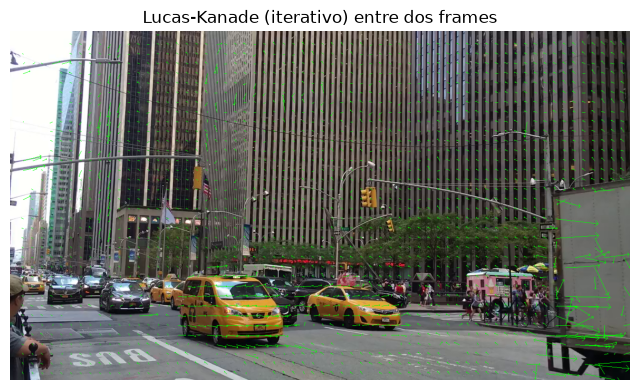

In [29]:
PASO = 20        # separación entre puntos de la rejilla
ESCALA = 5       # para ver mejor las flechas

def dibujar_flechas(frame, F, G, Fx, Fy):
    salida = frame.copy()
    alto, ancho = Fx.shape
    for y in range(R, alto - R, PASO):
        for x in range(R, ancho - R, PASO):
            h = lk_punto_iter(F, G, Fx, Fy, x, y)
            if h is None:
                continue
            fin = (int(x + ESCALA * h[0]), int(y + ESCALA * h[1]))
            cv2.arrowedLine(salida, (x, y), fin, (0, 255, 0), 1)
    return salida

resultado = dibujar_flechas(frame_nue, F, G, Fx, Fy)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))
plt.title("Lucas-Kanade (iterativo) entre dos frames")
plt.axis("off")
plt.show()

#### Reproducción de Video

In [ ]:
# >>>>>>>>>>  PONER AQUÍ LA RUTA DEL VÍDEO (otra vez)  <<<<<<<<<<
RUTA_VIDEO = "new_york.mp4"     # o 0 para la webcam

cap = cv2.VideoCapture(RUTA_VIDEO)
ok, frame_ant = cap.read()

if not ok:
    print("No se ha podido abrir el vídeo, revisa la ruta")
else:
    G = preparar(frame_ant)

    while ok:
        ok, frame = cap.read()
        if not ok:               # se acabó el vídeo
            break

        F = preparar(frame)
        Fx, Fy, _ = derivadas(F, G)
        salida = dibujar_flechas(frame, F, G, Fx, Fy)

        cv2.imshow('Lucas-Kanade', salida)

        G = F                    # el frame nuevo pasa a ser el anterior
        if cv2.waitKey(1) == 27: # Esc para salir
            break

cap.release()
cv2.destroyAllWindows()

TypeError: dibujar_flechas() missing 1 required positional argument: 'Fy'

## Qué no hemos hecho (y el paper sí)

- **No iteramos.** Solo hacemos un paso. El paper mueve $F$ según el $h$ obtenido y repite (ecuación 10).
- **No ponderamos** con $w(x)$ (ecuación 5).
- **No usamos pirámides** (coarse-fine). Por eso solo funciona con movimientos pequeños entre frames.
- **No incluimos rotación, escala ni brillo/contraste** (sección 4.6).

Si el movimiento es grande, las flechas salen mal o no salen, y una forma fácil de probar es saltarse frames o usar un vídeo con menos movimiento.